
# External calculators for DFT - GPAW

Many external calculators can be used with ASE. For Density-Functional Theory (DFT), they include GPAW, Abinit,
Vasp, Siesta, and Quantum ESPRESSO, see `supported calculators` for the
full list.




## GPAW
- GPAW is an electronic structure code implemented as a Python
   library with C backend.
- GPAW includes a few command line tools, but is generally
   always used with ASE.
- Due to this close relationship, many GPAW developers are also
   ASE developers.
- GPAW implements the projector-augmented wave (PAW) method which requires
   atomic “setups” with pseudopotentials.

In [ ]:
!pip install ase gpaw

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 18.9 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 76.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.5/71.5 MB 9.5 MB/s eta 0:00:00
  Created wheel for gpaw: filename=gpaw-26.7.0-cp313-cp313-linux_x86_64.whl size=4589820 sha256=434c058e58683775f0b8fb33a4d4b065076799662a3f8cf93d7ed7e15a272006
  Stored in directory: /root/.cache/pip/wheels/d4/12/42/3f3de7e0e80789820084bc7ac0b9c7a65c8b74d9f7f455e348
Successfully built gpaw


In [ ]:
from gpaw import GPAW, PW

from ase.build import bulk

atoms = bulk('C', 'diamond')

In [ ]:
atoms.calc = GPAW(xc='PBE', kpts=(4, 4, 4), mode=PW(500))

energy = atoms.get_potential_energy()
print(energy)

  __  _  _
 | _ |_)|_||  |
 |__||  | ||/\| - 26.7.0

User:   ???@38e5314a29bb
Date:   Sun Sep 20 20:06:18 2026
Arch:   x86_64
Pid:    4746
CWD:    /content
units:  Angstrom and eV
cores:  1
OpenMP: False

Versions:
  Python: 3.13.15
  ASE:    3.29.0
  Numpy:  2.1.3
  Scipy:  1.16.3
  Libxc:  2.x.y

Paths:
  gpaw:  /usr/local/lib/python3.13/dist-packages/gpaw
  _gpaw: /usr/local/lib/python3.13/dist-packages/
        _gpaw.cpython-313-x86_64-linux-gnu.so
  ase:   /usr/local/lib/python3.13/dist-packages/ase
  numpy: /usr/local/lib/python3.13/dist-packages/numpy
  scipy: /usr/local/lib/python3.13/dist-packages/scipy

Git-hashes:

OMP_NUM_THREADS: 


Environment variables:
  GPAW_CPUPY:          False
  GPAW_DEBUG:          False
  GPAW_MPI_BACKEND:    serial
  GPAW_MPI_OPTIONS:    None
  GPAW_NO_C_EXTENSION: False
  GPAW_NO_GPU_MPI:     False
  GPAW_TRACE:          False
  GPAW_USE_GPUS:       False

Input parameters:
  mode=PW(ecut=500.0),
  kpts=MonkhorstPack(size=array([4, 4, 4])),
  xc

  __  _  _
 | _ |_)|_||  |
 |__||  | ||/\| - 26.7.0

User:   ???@38e5314a29bb
Date:   Sun Sep 20 20:06:23 2026
Arch:   x86_64
Pid:    4746
CWD:    /content
units:  Angstrom and eV
cores:  1
OpenMP: False

Versions:
  Python: 3.13.15
  ASE:    3.29.0
  Numpy:  2.1.3
  Scipy:  1.16.3
  Libxc:  2.x.y

Paths:
  gpaw:  /usr/local/lib/python3.13/dist-packages/gpaw
  _gpaw: /usr/local/lib/python3.13/dist-packages/
        _gpaw.cpython-313-x86_64-linux-gnu.so
  ase:   /usr/local/lib/python3.13/dist-packages/ase
  numpy: /usr/local/lib/python3.13/dist-packages/numpy
  scipy: /usr/local/lib/python3.13/dist-packages/scipy

Git-hashes:

OMP_NUM_THREADS: 


Environment variables:
  GPAW_CPUPY:          False
  GPAW_DEBUG:          False
  GPAW_MPI_BACKEND:    serial
  GPAW_MPI_OPTIONS:    None
  GPAW_NO_C_EXTENSION: False
  GPAW_NO_GPU_MPI:     False
  GPAW_TRACE:          False
  GPAW_USE_GPUS:       False

Input parameters:
  mode=PW(ecut=700.0),
  kpts=MonkhorstPack(size=array([4, 4, 4])),
  xc

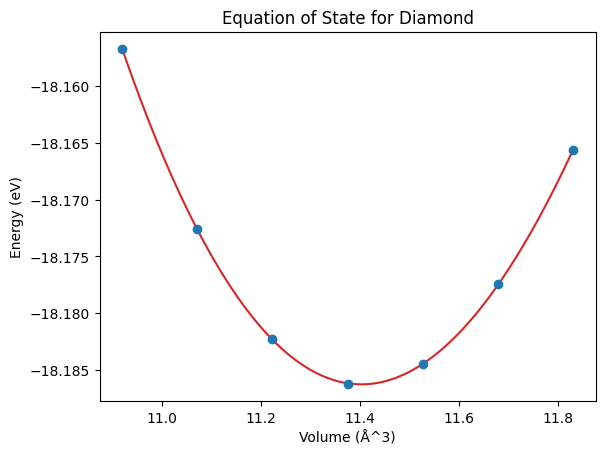

In [ ]:
from ase.build import bulk
from gpaw import GPAW, PW # Import GPAW and PW
from ase.eos import calculate_eos
from ase.units import kJ
import matplotlib.pyplot as plt # Import matplotlib for plotting

# Using Carbon (C) in diamond structure as in previous cells for consistency
atoms = bulk('C', 'diamond') # Changed from Cu to C

# Attach GPAW as a calculator with previously used parameters
# Increasing the cutoff energy to 700 eV for better accuracy, as per problem description.
atoms.calc = GPAW(xc='PBE', kpts=(4, 4, 4), mode=PW(700))

# Calculate equation of state with 7 points
eos = calculate_eos(atoms, npoints=7)
v0, e0, B = eos.fit()

a0 = (4*v0)**(1/3)

print("a0 =", a0)
print("Bulk modulus = ",B / kJ * 1.0e24, 'GPa')
ax = eos.plot(show=False)
plt.title('Equation of State for Diamond') # Add title to the plot
plt.xlabel('Volume (Å^3)') # Add x-axis label
plt.ylabel('Energy (eV)') # Add y-axis label
plt.show() # Display the plot

  __  _  _
 | _ |_)|_||  |
 |__||  | ||/\| - 26.7.0

User:   ???@38e5314a29bb
Date:   Sun Sep 20 20:07:04 2026
Arch:   x86_64
Pid:    4746
CWD:    /content
units:  Angstrom and eV
cores:  1
OpenMP: False

Versions:
  Python: 3.13.15
  ASE:    3.29.0
  Numpy:  2.1.3
  Scipy:  1.16.3
  Libxc:  2.x.y

Paths:
  gpaw:  /usr/local/lib/python3.13/dist-packages/gpaw
  _gpaw: /usr/local/lib/python3.13/dist-packages/
        _gpaw.cpython-313-x86_64-linux-gnu.so
  ase:   /usr/local/lib/python3.13/dist-packages/ase
  numpy: /usr/local/lib/python3.13/dist-packages/numpy
  scipy: /usr/local/lib/python3.13/dist-packages/scipy

Git-hashes:

OMP_NUM_THREADS: 


Environment variables:
  GPAW_CPUPY:          False
  GPAW_DEBUG:          False
  GPAW_MPI_BACKEND:    serial
  GPAW_MPI_OPTIONS:    None
  GPAW_NO_C_EXTENSION: False
  GPAW_NO_GPU_MPI:     False
  GPAW_TRACE:          False
  GPAW_USE_GPUS:       False

Input parameters:
  mode=PW(ecut=700.0),
  kpts=MonkhorstPack(size=array([4, 4, 4])),
  xc

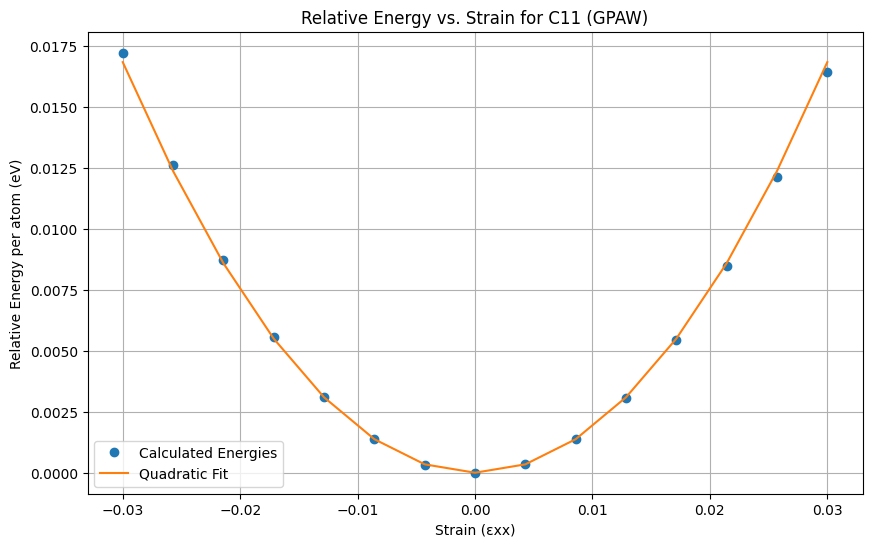

In [ ]:
from ase.build import bulk
from gpaw import GPAW, PW # Import GPAW and PW
from ase import units
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Use the fitted equilibrium lattice constant from part (a) for the unstrained crystal
# We use 'a0' which was calculated in the previous cell 'lXFbvkW6qRhy'
equilib_a = a0 # Using the equilibrium lattice constant from the previous calculation

# Create a conventional 4-atom cell for Carbon in diamond structure
al_equilibrium_atoms = bulk('C', 'diamond', a=equilib_a, cubic=True)
al_equilibrium_atoms.calc = GPAW(xc='PBE', kpts=(4, 4, 4), mode=PW(700)) # Use GPAW calculator
al_equilibrium_atoms.get_potential_energy() # Run initial calculation to get energy

# Calculate the actual potential energy of the unstrained equilibrium cell
# This will serve as the consistent reference for relative energies.
initial_total_energy = al_equilibrium_atoms.get_potential_energy()
initial_total_energy_per_atom = initial_total_energy / len(al_equilibrium_atoms)

initial_volume_per_atom = al_equilibrium_atoms.get_volume() / len(al_equilibrium_atoms)

print(f"Equilibrium lattice constant (a): {equilib_a:.4f} Å")
print(f"Initial energy per atom (calculated): {initial_total_energy_per_atom:.4f} eV")
print(f"Initial total energy (calculated for {len(al_equilibrium_atoms)} atoms): {initial_total_energy:.4f} eV")
print(f"Initial volume per atom: {initial_volume_per_atom:.4f} Å^3")



strains_xx = np.linspace(-0.03, 0.03, 15)

energies_c11 = []

for strain_xx in strains_xx:

    a_strained_x = equilib_a * (1 + strain_xx)

    cell_matrix = np.diag([a_strained_x, equilib_a, equilib_a])


    strained_al_crystal = al_equilibrium_atoms.copy()
    strained_al_crystal.set_cell(cell_matrix, scale_atoms=True)
    strained_al_crystal.calc = GPAW(xc='PBE', kpts=(4, 4, 4), mode=PW(700))

    energy = strained_al_crystal.get_potential_energy()
    energies_c11.append(energy)

energies_c11 = np.array(energies_c11)

# Energy relative to the initial unstrained total energy (per atom)
relative_energies_c11 = (energies_c11 - initial_total_energy) / len(al_equilibrium_atoms)

# Define the fitting function for C11: dE(εxx) = (V0_per_atom / 2) * C11 * εxx^2
def fit_c11(strain_xx, C11_coeff):

    return (initial_volume_per_atom / 2) * C11_coeff * strain_xx**2


initial_guess_c11_eV_per_A3 = 100 / 160.21766208

params_c11, covariance_c11 = curve_fit(fit_c11, strains_xx, relative_energies_c11, p0=[initial_guess_c11_eV_per_A3])

C11_eV_per_A3 = params_c11[0]
C11_GPa = C11_eV_per_A3 * 160.21766208

print(f"Calculated C11 (GPa): {C11_GPa:.4f}")


plt.figure(figsize=(10, 6))
plt.plot(strains_xx, relative_energies_c11, 'o', label='Calculated Energies')
plt.plot(np.sort(strains_xx), fit_c11(np.sort(strains_xx), *params_c11), '-', label='Quadratic Fit')
plt.xlabel('Strain (εxx)')
plt.ylabel('Relative Energy per atom (eV)')
plt.title('Relative Energy vs. Strain for C11 (GPAW)') # Update title
plt.legend()
plt.grid(True)
plt.show()

2.2 C12
-------

As in Lab 2, calculate C12 from B and C11 and report its value.

In [ ]:
# Calculate C12 using the relationship between B, C11, and C12 for cubic crystals
# B = (C11 + 2 * C12) / 3
# 3 * B = C11 + 2 * C12
# 2 * C12 = 3 * B - C11
# C12 = (3 * B - C11) / 2

C12_GPa = (3 * Bulk1 - C11_GPa) / 2
Bulk1 = B / kJ * 1.0e24

print(f"Calculated Bulk (GPa): {Bulk1:.4f}")
print(f"Calculated C12 (GPa): {C12_GPa:.4f}")

Calculated Bulk (GPa): 435.9388
Calculated C12 (GPa): 127.7876


2.3 C44
=======

You guessed it - adapt your previous code for the calculation of C44 and calculate C44 for diamond. **Provide value and plot.**

  __  _  _
 | _ |_)|_||  |
 |__||  | ||/\| - 26.7.0

User:   ???@38e5314a29bb
Date:   Sun Sep 20 21:13:48 2026
Arch:   x86_64
Pid:    4746
CWD:    /content
units:  Angstrom and eV
cores:  1
OpenMP: False

Versions:
  Python: 3.13.15
  ASE:    3.29.0
  Numpy:  2.1.3
  Scipy:  1.16.3
  Libxc:  2.x.y

Paths:
  gpaw:  /usr/local/lib/python3.13/dist-packages/gpaw
  _gpaw: /usr/local/lib/python3.13/dist-packages/
        _gpaw.cpython-313-x86_64-linux-gnu.so
  ase:   /usr/local/lib/python3.13/dist-packages/ase
  numpy: /usr/local/lib/python3.13/dist-packages/numpy
  scipy: /usr/local/lib/python3.13/dist-packages/scipy

Git-hashes:

OMP_NUM_THREADS: 


Environment variables:
  GPAW_CPUPY:          False
  GPAW_DEBUG:          False
  GPAW_MPI_BACKEND:    serial
  GPAW_MPI_OPTIONS:    None
  GPAW_NO_C_EXTENSION: False
  GPAW_NO_GPU_MPI:     False
  GPAW_TRACE:          False
  GPAW_USE_GPUS:       False

Input parameters:
  mode=PW(ecut=700.0),
  kpts=MonkhorstPack(size=array([4, 4, 4])),
  xc

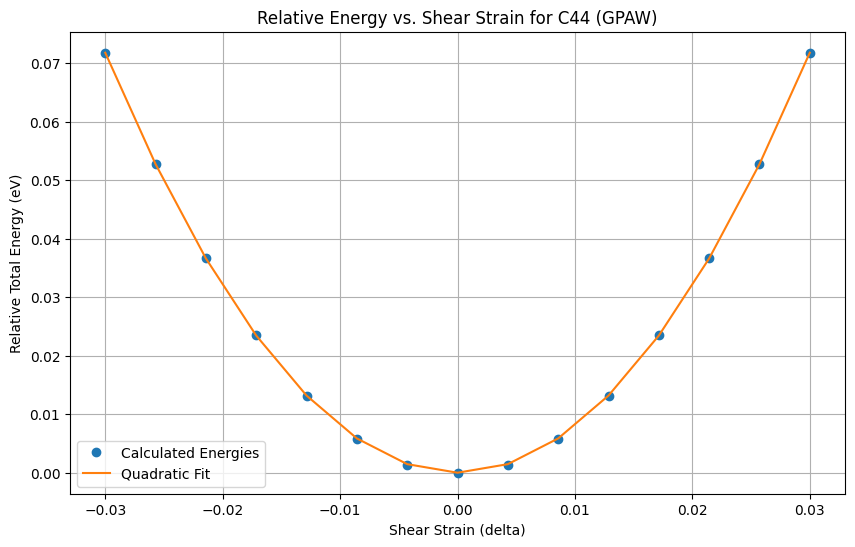

In [ ]:
from ase.build import bulk
from gpaw import GPAW, PW # Import GPAW and PW
from ase import units
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit


equilib_a = a0
initial_total_energy = initial_total_energy
initial_volume_per_atom = initial_volume_per_atom

strains_shear = np.linspace(-0.03, 0.03, 15)

energies_c44 = []


al_equilibrium_atoms = bulk('C', 'diamond', a=equilib_a, cubic=True)
al_equilibrium_atoms.calc = GPAW(xc='PBE', kpts=(4, 4, 4), mode=PW(700))

base_cell_vectors = al_equilibrium_atoms.cell.array

V0_total_cell = al_equilibrium_atoms.get_volume()

for shear_delta in strains_shear:

    strained_cell_vectors = base_cell_vectors.copy()
    strained_cell_vectors[2, 0] = equilib_a * shear_delta


    strained_al_crystal = al_equilibrium_atoms.copy()
    strained_al_crystal.set_cell(strained_cell_vectors, scale_atoms=True)
    strained_al_crystal.calc = GPAW(xc='PBE', kpts=(4, 4, 4), mode=PW(700))

    energy = strained_al_crystal.get_potential_energy()
    energies_c44.append(energy)

energies_c44 = np.array(energies_c44)


relative_energies_c44 = (energies_c44 - initial_total_energy)

def fit_c44(shear_delta, C44_coeff):

    return (V0_total_cell / 2) * C44_coeff * shear_delta**2


initial_guess_c44_eV_per_A3 = 50 / 160.21766208

params_c44, covariance_c44 = curve_fit(fit_c44, strains_shear, relative_energies_c44, p0=[initial_guess_c44_eV_per_A3])

C44_eV_per_A3 = params_c44[0]

C44_GPa = C44_eV_per_A3 * 160.21766208

print(f"Calculated C44 (GPa): {C44_GPa:.4f}")

plt.figure(figsize=(10, 6))
plt.plot(strains_shear, relative_energies_c44, 'o', label='Calculated Energies')
plt.plot(np.sort(strains_shear), fit_c44(np.sort(strains_shear), *params_c44), '-', label='Quadratic Fit')
plt.xlabel('Shear Strain (delta)')
plt.ylabel('Relative Total Energy (eV)')
plt.title('Relative Energy vs. Shear Strain for C44 (GPAW)')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import pandas as pd

# Calculated values from the previous steps
calculated_bulk = Bulk1
calculated_c11 = C11_GPa
calculated_c12 = C12_GPa
calculated_c44 = C44_GPa

# Experimental values for Diamond (in GPa)
experimental_bulk = 442 # GPa
experimental_c11 = 1079 # GPa
experimental_c12 = 124  # GPa
experimental_c44 = 578  # GPa

data = {
    'Elastic Constant': ['Bulk Modulus (B)', 'C11', 'C12', 'C44'],
    'Calculated (GPa)': [calculated_bulk, calculated_c11, calculated_c12, calculated_c44],
    'Experimental (GPa)': [experimental_bulk, experimental_c11, experimental_c12, experimental_c44]
}

# Create the DataFrame
df_elastic_constants = pd.DataFrame(data)

# Calculate percentage error
df_elastic_constants['Percentage Error (%)'] = (
    (df_elastic_constants['Calculated (GPa)'] - df_elastic_constants['Experimental (GPa)'])
    / df_elastic_constants['Experimental (GPa)'] * 100
)

display(df_elastic_constants)


,Elastic Constant,Calculated (GPa),Experimental (GPa),Percentage Error (%)
0,Bulk Modulus (B),435.938758,442,-1.371322
1,C11,1052.240976,1079,-2.479984
2,C12,127.787649,124,3.054556
3,C44,560.101146,578,-3.096688


3. Band Structures
==================

Provide solutions for the attached worksheet which follows very closely what we did in class yesterday.